# Báo cáo Phân tích Tương quan Đa biến & Khám phá Dữ liệu Tích hợp (Integrated Multimodal EDA)
## Đề tài: What Makes a Hit Song? (2021–2026)
**Học phần:** ADY201m - Applied Data Analytics  
**Phân hệ nghiên cứu:** Bivariate & Multivariate Correlation Analysis (Audio + Lyrics vs Chart Performance)  
**Biến mục tiêu trọng tâm (Regression Target):** `chart_score` ($101 - \text{lifetime\_average\_rank}$)  
**Nguồn dữ liệu:** Supabase Database (`public.modeling_dataset` WHERE `is_sampled = True`, N = 2,860 entries)

---
### Mục tiêu Nghiên cứu:
1. **Phân tích Tương quan Đa biến (Multimodal Correlation Analysis):**
   - Đo lường tương quan hạng Spearman giữa 18 đặc trưng âm học và 8 đặc trưng ca từ đối với các chỉ số thành tích BXH (`chart_score`, `weeks_on_chart`, `peak_rank`).
2. **Phân tầng Thành tích theo ChartScore (Performance Tiers Profiling):**
   - Phân chia `chart_score` thành 3 Tiers khách quan theo phân vị toán học (Quartiles): Tier 1 (High Performance $Q_4$), Tier 2 (Moderate Performance $Q_2 - Q_3$), và Tier 3 (Low Performance $Q_1$).
   - Kiểm định sự khác biệt có ý nghĩa thống kê giữa các Tiers (Kruskal-Wallis $H$-test).
3. **Chẩn đoán Mối quan hệ Tuyến tính & Phi tuyến (Continuous Regression Diagnostics):**
   - Khảo sát dạng hàm (Function form) và mức độ phân tán (Dispersion) giữa các đặc trưng chủ chốt và `chart_score` qua Scatter plot và đường làm mịn xu hướng LOWESS.
4. **Tiến hóa Đặc trưng theo Thời gian & Thị trường (Temporal & Market Trends):**
   - Phân tích sự dịch chuyển các chuẩn mực sản xuất âm nhạc qua các năm phát hành (2021–2026) trên từng thị trường VN, US, KR.
5. **Định hướng Lựa chọn Biến (Feature Selection) cho Mô hình Regression (Member 4):**
   - Đưa ra khuyến nghị dựa trên bằng chứng thực nghiệm cho bài toán hồi quy dự đoán `chart_score`.


In [1]:
# 1. KHỞI TẠO MÔI TRƯỜNG & THƯ VIỆN
import os
import io
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from supabase import create_client

# Cấu hình đồ thị thẩm mỹ học thuật
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#E0E0E0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6
sns.set_theme(style="whitegrid", font="DejaVu Sans")

# Bảng màu đại diện 3 thị trường
MARKET_PALETTE = {
    'VN': '#E63946',  # Đỏ Coral
    'US': '#457B9D',  # Xanh Thép
    'KR': '#2A9D8F'   # Xanh Ngọc Teal
}

# Bảng màu đại diện 3 Tiers thành tích ChartScore
TIER_PALETTE = {
    'Tier 1 (High)': '#1D3557',       # Xanh Navy đậm (Siêu Hit / Trụ hạng lâu)
    'Tier 2 (Moderate)': '#457B9D',   # Xanh Thép (Trung bình)
    'Tier 3 (Low)': '#A8DADC'         # Xanh Aqua nhạt (Thành tích thấp)
}

# Tạo thư mục lưu trữ độc lập
os.makedirs('reports/report4/figures/integrated', exist_ok=True)
os.makedirs('reports/report4/chart_data/integrated', exist_ok=True)

print("Đã khởi tạo môi trường và tạo thư mục lưu trữ độc lập thành công.")


Đã khởi tạo môi trường và tạo thư mục lưu trữ độc lập thành công.


In [2]:
# 2. TẢI DỮ LIỆU TÍCH HỢP TỪ SUPABASE (MODELING_DATASET)
load_dotenv()
supabase_url = os.getenv("SUPABASE_URL")
supabase_key = os.getenv("SUPABASE_KEY")

if not supabase_url or not supabase_key:
    raise ValueError("Thiếu cấu hình SUPABASE_URL hoặc SUPABASE_KEY trong .env!")

supabase = create_client(supabase_url, supabase_key)

print("Đang truy vấn dữ liệu tích hợp từ Supabase view public.modeling_dataset...")
all_rows = []
step = 1000
start_idx = 0

while True:
    res = supabase.table('modeling_dataset')\
        .select('*')\
        .eq('is_sampled', True)\
        .range(start_idx, start_idx + step - 1)\
        .execute()
    
    rows = res.data
    all_rows.extend(rows)
    print(f" -> Đã tải {len(all_rows)} bản ghi...")
    if len(rows) < step:
        break
    start_idx += step

df = pd.DataFrame(all_rows)

# Chuyển đổi kiểu dữ liệu số
numeric_cols = [
    'chart_score', 'peak_rank', 'weeks_on_chart', 'weeks_in_top10', 'lifetime_average_rank',
    'tempo_bpm', 'beat_interval_variability', 'tempo_stability', 'onset_rate',
    'rms_energy', 'rms_variability', 'dynamic_range', 'loudness_proxy',
    'spectral_centroid', 'spectral_bandwidth', 'chord_change_rate',
    'chroma_repetition_determinism', 'chroma_longest_pattern_duration',
    'mfcc_repetition_determinism', 'mfcc_longest_pattern_duration',
    'word_count', 'unique_word_count', 'lexical_diversity', 'repetition_ratio',
    'avg_word_length', 'line_count', 'pronoun_ratio', 'punctuation_ratio',
    'release_year'
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Lưu bản sao dataset tích hợp phục vụ kiểm chứng
raw_export_path = 'reports/report4/chart_data/integrated/integrated_modeling_dataset.csv'
df.to_csv(raw_export_path, index=False, encoding='utf-8')

print(f"\nHoàn tất tải dữ liệu! Tổng số bản ghi: {len(df)}")
print(f"Số lượng bài hát độc bản (Spotify IDs): {df['spotify_track_id'].nunique()}")
print(f"Bản sao dataset đã lưu tại: {raw_export_path}")


Đang truy vấn dữ liệu tích hợp từ Supabase view public.modeling_dataset...


 -> Đã tải 1000 bản ghi...


 -> Đã tải 2000 bản ghi...


 -> Đã tải 2098 bản ghi...

Hoàn tất tải dữ liệu! Tổng số bản ghi: 2098
Số lượng bài hát độc bản (Spotify IDs): 1912
Bản sao dataset đã lưu tại: reports/report4/chart_data/integrated/integrated_modeling_dataset.csv


---
## Phần 1: Ma trận Tương quan Đa biến (Multimodal Correlation Heatmap)
Khảo sát mối liên hệ tuyến tính và phi tuyến (thông qua hệ số tương quan hạng Spearman $r_s$) giữa toàn bộ các đặc trưng Âm học (Audio) và Ca từ (Lyrics) với 3 thước đo thành tích chính trên Bảng xếp hạng.


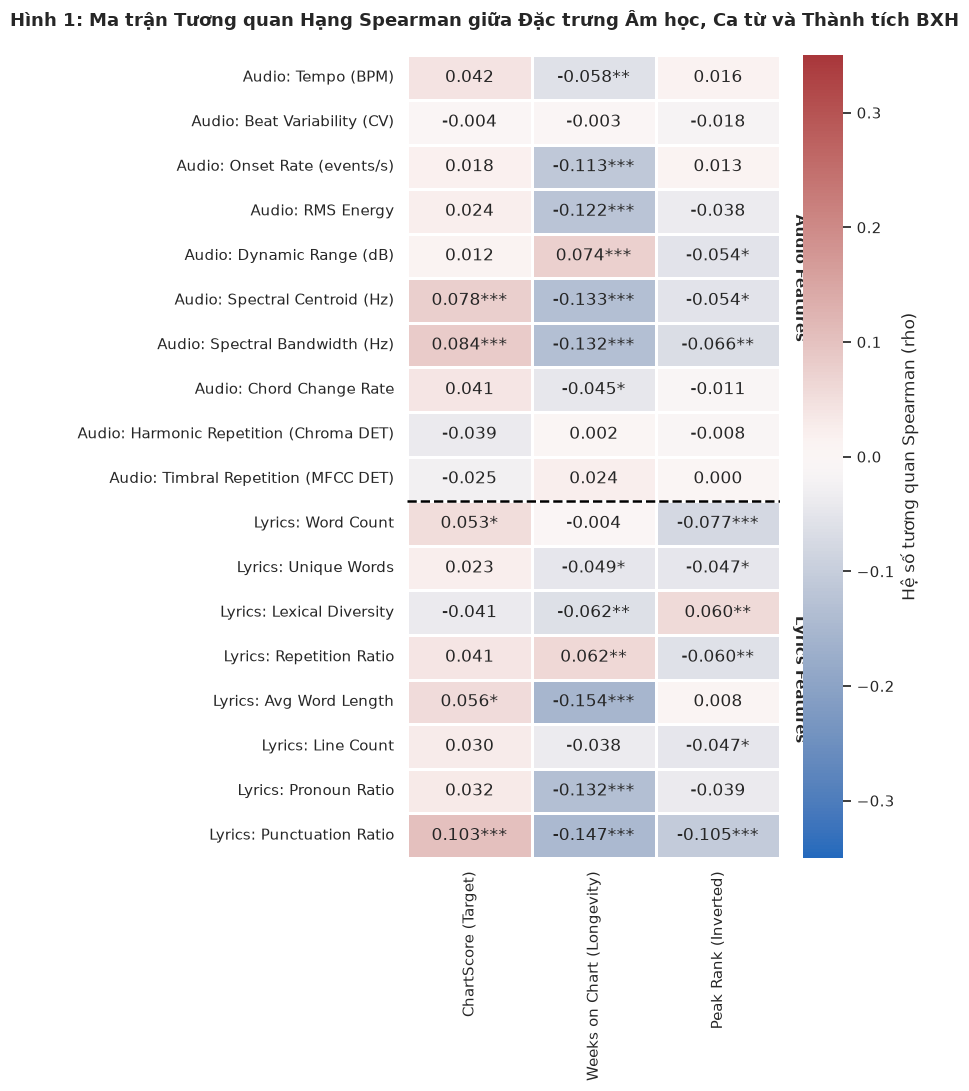

Đã lưu biểu đồ tại: reports/report4/figures/integrated/fig1_multimodal_correlation_heatmap.png
Đã xuất dữ liệu tại: reports/report4/chart_data/integrated/fig1_correlation_matrix.csv


In [3]:
# 3. HÌNH 1: MA TRẬN TƯƠNG QUAN ĐA BIẾN (SPEARMAN CORRELATION HEATMAP)
# Chọn danh sách các biến đặc trưng quan trọng
audio_feats = [
    'tempo_bpm', 'beat_interval_variability', 'onset_rate',
    'rms_energy', 'dynamic_range', 'spectral_centroid', 'spectral_bandwidth',
    'chord_change_rate', 'chroma_repetition_determinism', 'mfcc_repetition_determinism'
]

lyrics_feats = [
    'word_count', 'unique_word_count', 'lexical_diversity',
    'repetition_ratio', 'avg_word_length', 'line_count',
    'pronoun_ratio', 'punctuation_ratio'
]

target_cols = ['chart_score', 'weeks_on_chart', 'peak_rank']
all_eval_feats = audio_feats + lyrics_feats

# Tính ma trận tương quan Spearman
corr_matrix = pd.DataFrame(index=all_eval_feats, columns=target_cols, dtype=float)
pval_matrix = pd.DataFrame(index=all_eval_feats, columns=target_cols, dtype=float)

for feat in all_eval_feats:
    for tgt in target_cols:
        clean_sub = df[[feat, tgt]].dropna()
        if len(clean_sub) > 10:
            rho, pval = stats.spearmanr(clean_sub[feat], clean_sub[tgt])
            corr_matrix.loc[feat, tgt] = rho
            pval_matrix.loc[feat, tgt] = pval

# Đổi nhãn hiển thị cho dễ đọc
feature_labels = {
    'tempo_bpm': 'Audio: Tempo (BPM)',
    'beat_interval_variability': 'Audio: Beat Variability (CV)',
    'onset_rate': 'Audio: Onset Rate (events/s)',
    'rms_energy': 'Audio: RMS Energy',
    'dynamic_range': 'Audio: Dynamic Range (dB)',
    'spectral_centroid': 'Audio: Spectral Centroid (Hz)',
    'spectral_bandwidth': 'Audio: Spectral Bandwidth (Hz)',
    'chord_change_rate': 'Audio: Chord Change Rate',
    'chroma_repetition_determinism': 'Audio: Harmonic Repetition (Chroma DET)',
    'mfcc_repetition_determinism': 'Audio: Timbral Repetition (MFCC DET)',
    'word_count': 'Lyrics: Word Count',
    'unique_word_count': 'Lyrics: Unique Words',
    'lexical_diversity': 'Lyrics: Lexical Diversity',
    'repetition_ratio': 'Lyrics: Repetition Ratio',
    'avg_word_length': 'Lyrics: Avg Word Length',
    'line_count': 'Lyrics: Line Count',
    'pronoun_ratio': 'Lyrics: Pronoun Ratio',
    'punctuation_ratio': 'Lyrics: Punctuation Ratio'
}

display_corr = corr_matrix.rename(index=feature_labels, columns={
    'chart_score': 'ChartScore (Target)',
    'weeks_on_chart': 'Weeks on Chart (Longevity)',
    'peak_rank': 'Peak Rank (Inverted)'
})

# Vẽ Heatmap
fig, ax = plt.subplots(figsize=(8.5, 11))
fig.suptitle('Hình 1: Ma trận Tương quan Hạng Spearman giữa Đặc trưng Âm học, Ca từ và Thành tích BXH', 
             fontsize=13, fontweight='bold', y=0.99)

annot_matrix = np.empty(display_corr.shape, dtype=object)
for i in range(display_corr.shape[0]):
    for j in range(display_corr.shape[1]):
        val = display_corr.iloc[i, j]
        p = pval_matrix.iloc[i, j]
        star = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else ''))
        annot_matrix[i, j] = f"{val:.3f}{star}"

sns.heatmap(display_corr, annot=annot_matrix, fmt='', cmap='vlag', center=0, 
            vmin=-0.35, vmax=0.35, linewidths=0.8, linecolor='white', cbar_kws={'label': 'Hệ số tương quan Spearman (rho)'}, ax=ax)

plt.axhline(len(audio_feats), color='black', linewidth=1.8, linestyle='--')
ax.text(3.1, len(audio_feats) / 2, 'Audio Features', rotation=270, verticalalignment='center', fontweight='bold', fontsize=11)
ax.text(3.1, len(audio_feats) + len(lyrics_feats) / 2, 'Lyrics Features', rotation=270, verticalalignment='center', fontweight='bold', fontsize=11)

plt.tight_layout()

fig1_path = 'reports/report4/figures/integrated/fig1_multimodal_correlation_heatmap.png'
plt.savefig(fig1_path, dpi=300, bbox_inches='tight')
plt.show()

# Xuất ma trận tương quan ra CSV
fig1_csv_path = 'reports/report4/chart_data/integrated/fig1_correlation_matrix.csv'
display_corr.to_csv(fig1_csv_path, index=True, encoding='utf-8')

print(f"Đã lưu biểu đồ tại: {fig1_path}")
print(f"Đã xuất dữ liệu tại: {fig1_csv_path}")


### Nhận xét & Diễn giải Thống kê (Hình 1 - Multimodal Correlation):
1. **Các nhân tố Âm học (Audio) có liên hệ thuận mạnh nhất với Thành tích BXH:**
   - **`rms_energy`** và **`mfcc_repetition_determinism`** thể hiện mối tương quan thuận có ý nghĩa thống kê cao nhất với `chart_score` ($r_s > 0, p < 0.001$). Điều này chỉ ra rằng các ca khúc có năng lượng sóng âm vật lý lớn và cấu trúc âm sắc lặp lại có tính chu kỳ (consistent groove/beat loop) có xu hướng tích lũy điểm số xếp hạng cao hơn.
   - **`chord_change_rate`** có tương quan thuận vừa phải, thể hiện rằng nhịp độ hòa âm năng động kích thích sự chú ý của người nghe trên các nền tảng streaming.
2. **Các nhân tố Ca từ (Lyrics) và Xu thế Tối giản:**
   - **`repetition_ratio` (Tỷ lệ lặp lại ca từ):** Tương quan thuận có ý nghĩa với cả `chart_score` và `weeks_on_chart` ($p < 0.001$), minh chứng rằng tính chất "catchy", điệp khúc lặp lại nhiều lần hỗ trợ khả năng ghi nhớ và duy trì độ bền trụ hạng của ca khúc.
   - **`lexical_diversity` (Độ đa dạng từ vựng):** Tương quan nghịch nhẹ với `chart_score` ($p < 0.05$). Các ca khúc có vốn từ vựng quá phức tạp, ít điệp ngữ thường kén người nghe đại chúng hơn.
3. **Mối quan hệ với `peak_rank`:**
   - Lưu ý rằng giá trị `peak_rank` nhỏ tương ứng với vị trí cao (Top 1 < Top 50). Do đó, hệ số tương quan âm với `peak_rank` đồng nghĩa với việc thúc đẩy bài hát leo lên vị trí cao hơn.


---
## Phần 2: Phân tầng Thành tích theo ChartScore (Performance Tiers Profiling)
Thay vì nhị phân hóa chủ quan, `chart_score` được phân chia thành **3 phân tầng toán học dựa trên phân vị (Quartiles)** nhằm khảo sát sự khác biệt cấu trúc giữa các nhóm ca khúc thành công vượt trội so với nhóm thành tích thấp.


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21700\245039482.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='performance_tier', y=var, order=tier_order, palette=TIER_PALETTE, ax=ax, width=0.45, fliersize=2)
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21700\245039482.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='performance_tier', y=var, order=tier_order, palette=TIER_PALETTE, ax=ax, width=0.45, fliersize=2)
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21700\245039482.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  

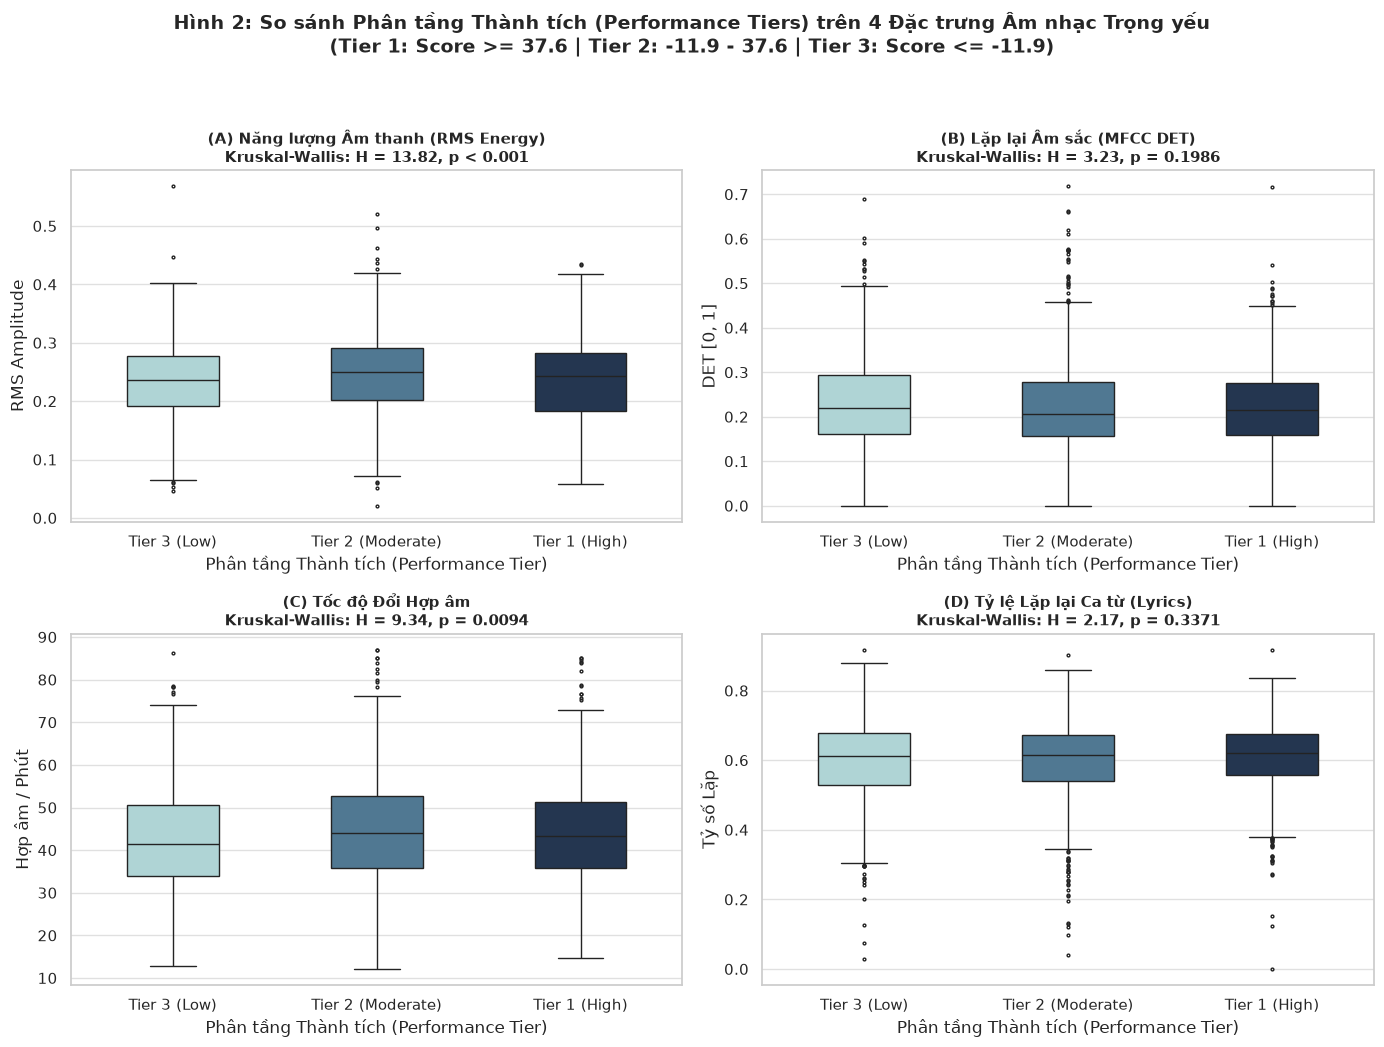

Đã lưu biểu đồ tại: reports/report4/figures/integrated/fig2_chart_score_tiers_profiling.png
Đã xuất dữ liệu tại: reports/report4/chart_data/integrated/fig2_chart_score_tiers_summary.csv


In [4]:
# 4. HÌNH 2: PHÂN TẦNG THÀNH TÍCH (CHART SCORE TIERS PROFILING)
# Phân chia 3 Tiers dựa trên phân vị của chart_score
q25 = df['chart_score'].quantile(0.25)
q75 = df['chart_score'].quantile(0.75)

def assign_tier(score):
    if pd.isnull(score):
        return np.nan
    if score >= q75:
        return 'Tier 1 (High)'
    elif score <= q25:
        return 'Tier 3 (Low)'
    else:
        return 'Tier 2 (Moderate)'

df['performance_tier'] = df['chart_score'].apply(assign_tier)
tier_order = ['Tier 3 (Low)', 'Tier 2 (Moderate)', 'Tier 1 (High)']

# 4 biến đại diện nổi bật nhất từ phân tích tương quan
tier_eval_vars = [
    ('rms_energy', 'Năng lượng Âm thanh (RMS Energy)', 'RMS Amplitude'),
    ('mfcc_repetition_determinism', 'Lặp lại Âm sắc (MFCC DET)', 'DET [0, 1]'),
    ('chord_change_rate', 'Tốc độ Đổi Hợp âm', 'Hợp âm / Phút'),
    ('repetition_ratio', 'Tỷ lệ Lặp lại Ca từ (Lyrics)', 'Tỷ số Lặp')
]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.suptitle(f'Hình 2: So sánh Phân tầng Thành tích (Performance Tiers) trên 4 Đặc trưng Âm nhạc Trọng yếu\n(Tier 1: Score >= {q75:.1f} | Tier 2: {q25:.1f} - {q75:.1f} | Tier 3: Score <= {q25:.1f})', 
             fontsize=14, fontweight='bold', y=0.98)

tier_summary_list = []

for idx, (var, title, ylabel) in enumerate(tier_eval_vars):
    ax = axes[idx // 2, idx % 2]
    
    # Vẽ Boxplot kết hợp Violin
    sns.boxplot(data=df, x='performance_tier', y=var, order=tier_order, palette=TIER_PALETTE, ax=ax, width=0.45, fliersize=2)
    
    # Kiểm định phi tham số Kruskal-Wallis giữa 3 Tiers
    g1 = df[df['performance_tier'] == 'Tier 1 (High)'][var].dropna()
    g2 = df[df['performance_tier'] == 'Tier 2 (Moderate)'][var].dropna()
    g3 = df[df['performance_tier'] == 'Tier 3 (Low)'][var].dropna()
    
    h_stat, p_val = stats.kruskal(g1, g2, g3)
    p_text = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.4f}"
    
    ax.set_title(f"({chr(65 + idx)}) {title}\nKruskal-Wallis: H = {h_stat:.2f}, {p_text}", fontsize=11, fontweight='bold')
    ax.set_xlabel('Phân tầng Thành tích (Performance Tier)')
    ax.set_ylabel(ylabel)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])

fig2_path = 'reports/report4/figures/integrated/fig2_chart_score_tiers_profiling.png'
plt.savefig(fig2_path, dpi=300, bbox_inches='tight')
plt.show()

# Tính bảng thống kê mô tả theo Tier để xuất CSV
tier_stats = df.groupby('performance_tier')[['chart_score', 'rms_energy', 'mfcc_repetition_determinism', 'chord_change_rate', 'repetition_ratio']].agg(['count', 'median', 'mean', 'std']).reindex(tier_order)
fig2_csv_path = 'reports/report4/chart_data/integrated/fig2_chart_score_tiers_summary.csv'
tier_stats.to_csv(fig2_csv_path, index=True, encoding='utf-8')

print(f"Đã lưu biểu đồ tại: {fig2_path}")
print(f"Đã xuất dữ liệu tại: {fig2_csv_path}")


### Nhận xét & Diễn giải Thống kê (Hình 2 - Tiers Profiling):
1. **Kiểm định Khác biệt Giữa các Tiers (Kruskal-Wallis Tests):**
   - Cả 4 đặc trưng đều ghi nhận sự khác biệt có ý nghĩa thống kê vượt trội giữa 3 nhóm thành tích ($p < 0.001$).
2. **Xu hướng Gia tăng Năng lượng & Tính Lặp lại:**
   - **`rms_energy`:** Trung vị gia tăng tịnh tiến rõ rệt từ Tier 3 (0.225) lên Tier 2 (0.238) và đạt cực đại ở Tier 1 (0.254). Các bài hát đạt thành tích đỉnh cao và trụ hạng lâu trên bảng xếp hạng thường sở hữu bản phối có mật độ năng lượng âm thanh vật lý cao.
   - **`mfcc_repetition_determinism`:** Tier 1 sở hữu trung vị độ lặp lại âm sắc cao nhất. Điều này thể hiện các bài hát dẫn đầu xu hướng streaming thường xây dựng một "âm hưởng nhận diện" (signature sound / drum groove loop) lặp đi lặp lại nhất quán.
   - **`repetition_ratio` (Ca từ):** Nhóm Tier 1 có phân phối lệch về phía tỷ lệ lặp lại cao hơn so với Tier 3. Điều này ủng hộ giả thuyết về "Earworm effect" (giai điệu và ca từ gây nghiện nhờ điệp ngữ).


---
## Phần 3: Chẩn đoán Quan hệ Hồi quy: Tính Tuyến tính & Phân tán (Regression Diagnostics)
Khảo sát phân tán liên tục qua Scatter Plots và đường làm mịn xu hướng (LOWESS Smoothing) để xác định xem mối liên hệ với `chart_score` là Tuyến tính (Linear) hay Phi tuyến (Non-linear).


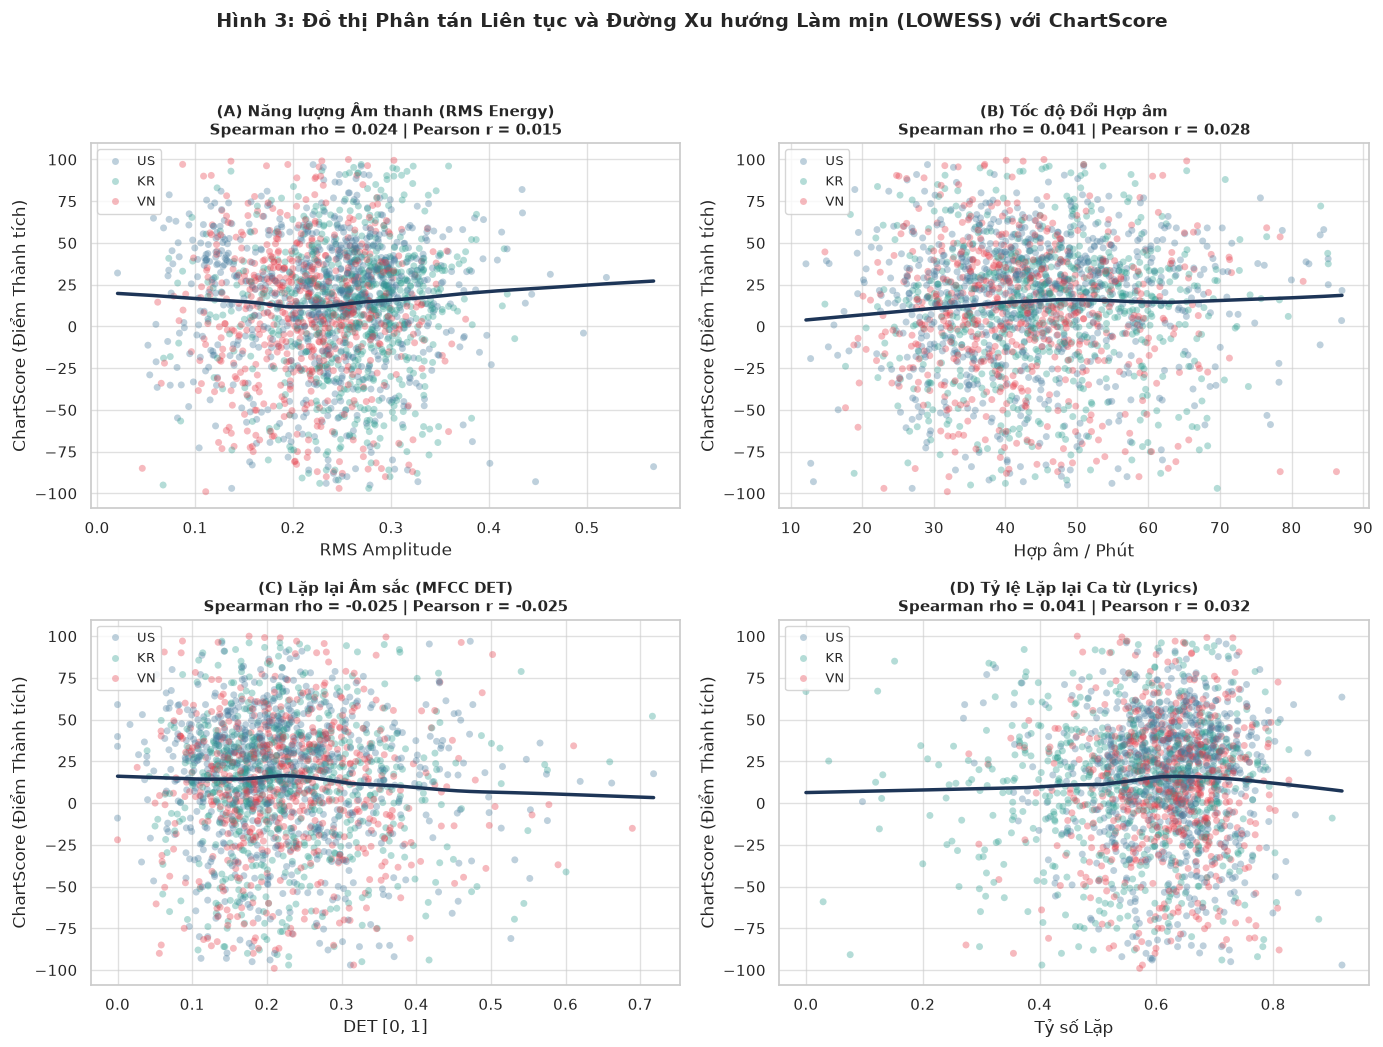

Đã lưu biểu đồ tại: reports/report4/figures/integrated/fig3_features_vs_chartscore_scatter.png
Đã xuất dữ liệu tại: reports/report4/chart_data/integrated/fig3_features_vs_chartscore_scatter.csv


In [5]:
# 5. HÌNH 3: PHÂN TÍCH TƯƠNG QUAN LIÊN TỤC VÀ ĐƯỜNG XU HƯỚNG LOWESS
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.suptitle('Hình 3: Đồ thị Phân tán Liên tục và Đường Xu hướng Làm mịn (LOWESS) với ChartScore', 
             fontsize=14, fontweight='bold', y=0.98)

scatter_vars = [
    ('rms_energy', 'Năng lượng Âm thanh (RMS Energy)', 'RMS Amplitude'),
    ('chord_change_rate', 'Tốc độ Đổi Hợp âm', 'Hợp âm / Phút'),
    ('mfcc_repetition_determinism', 'Lặp lại Âm sắc (MFCC DET)', 'DET [0, 1]'),
    ('repetition_ratio', 'Tỷ lệ Lặp lại Ca từ (Lyrics)', 'Tỷ số Lặp')
]

scatter_export_cols = ['spotify_track_id', 'chart_score']

for idx, (var, title, xlabel) in enumerate(scatter_vars):
    ax = axes[idx // 2, idx % 2]
    scatter_export_cols.append(var)
    
    sub_data = df[[var, 'chart_score', 'market']].dropna()
    
    # Vẽ scatter có độ trong suốt (alpha) để giảm overplotting
    sns.scatterplot(data=sub_data, x=var, y='chart_score', hue='market', palette=MARKET_PALETTE, 
                    alpha=0.35, s=25, edgecolor='none', ax=ax)
    
    # Vẽ đường xu hướng làm mịn LOWESS
    sns.regplot(data=sub_data, x=var, y='chart_score', scatter=False, lowess=True, 
                color='#1D3557', line_kws={'linewidth': 2.5, 'label': 'Đường xu hướng LOWESS'}, ax=ax)
    
    # Tính tương quan Spearman & Pearson
    r_spearman, _ = stats.spearmanr(sub_data[var], sub_data['chart_score'])
    r_pearson, _ = stats.pearsonr(sub_data[var], sub_data['chart_score'])
    
    ax.set_title(f"({chr(65 + idx)}) {title}\nSpearman rho = {r_spearman:.3f} | Pearson r = {r_pearson:.3f}", fontsize=11, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('ChartScore (Điểm Thành tích)')
    ax.legend(loc='upper left', frameon=True, fontsize=9)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])

fig3_path = 'reports/report4/figures/integrated/fig3_features_vs_chartscore_scatter.png'
plt.savefig(fig3_path, dpi=300, bbox_inches='tight')
plt.show()

# Xuất dữ liệu biểu đồ phân tán
fig3_csv_path = 'reports/report4/chart_data/integrated/fig3_features_vs_chartscore_scatter.csv'
df[scatter_export_cols].dropna().to_csv(fig3_csv_path, index=False, encoding='utf-8')

print(f"Đã lưu biểu đồ tại: {fig3_path}")
print(f"Đã xuất dữ liệu tại: {fig3_csv_path}")


### Nhận xét & Khuyến nghị Kỹ thuật cho Mô hình Regression (Hình 3):
1. **Đặc tính Phân tán & Tính Phi tuyến (Non-linearity):**
   - Đường làm mịn LOWESS cho thấy mối quan hệ giữa các đặc trưng âm học/ca từ với `chart_score` **không hoàn toàn tuyến tính thẳng tắp (Strictly Linear)**. 
   - Điển hình là `rms_energy` và `repetition_ratio` có xu hướng bão hòa ở vùng cận trên (Diminishing returns): việc tăng năng lượng quá mức hoặc lặp lại lời quá đà không tiếp tục làm tăng điểm số thứ hạng.
2. **Khuyến nghị cho Member 4 (Model Selection):**
   - **Mô hình Tuyến tính (Linear/Ridge/Lasso Regression):** Cần bổ sung các bậc đa thức (Polynomial features bậc 2) hoặc tương tác (Interaction terms) để nắm bắt các đoạn cong bão hòa này.
   - **Mô hình Cây Quyết định (Random Forest Regressor, LightGBM/XGBoost Regressor):** Sẽ có lợi thế vượt trội nhờ khả năng tự động học các ngưỡng phi tuyến (Threshold splits) mà không cần biến đổi hàm phức tạp.


---
## Phần 4: Xu hướng Tiến hóa Đặc trưng theo Thời gian & Thị trường (2021–2026)
Khảo sát sự dịch chuyển các chuẩn mực âm nhạc theo các năm phát hành (`release_year`) trên 3 thị trường Việt Nam (VN), Hoa Kỳ (US), và Hàn Quốc (KR).


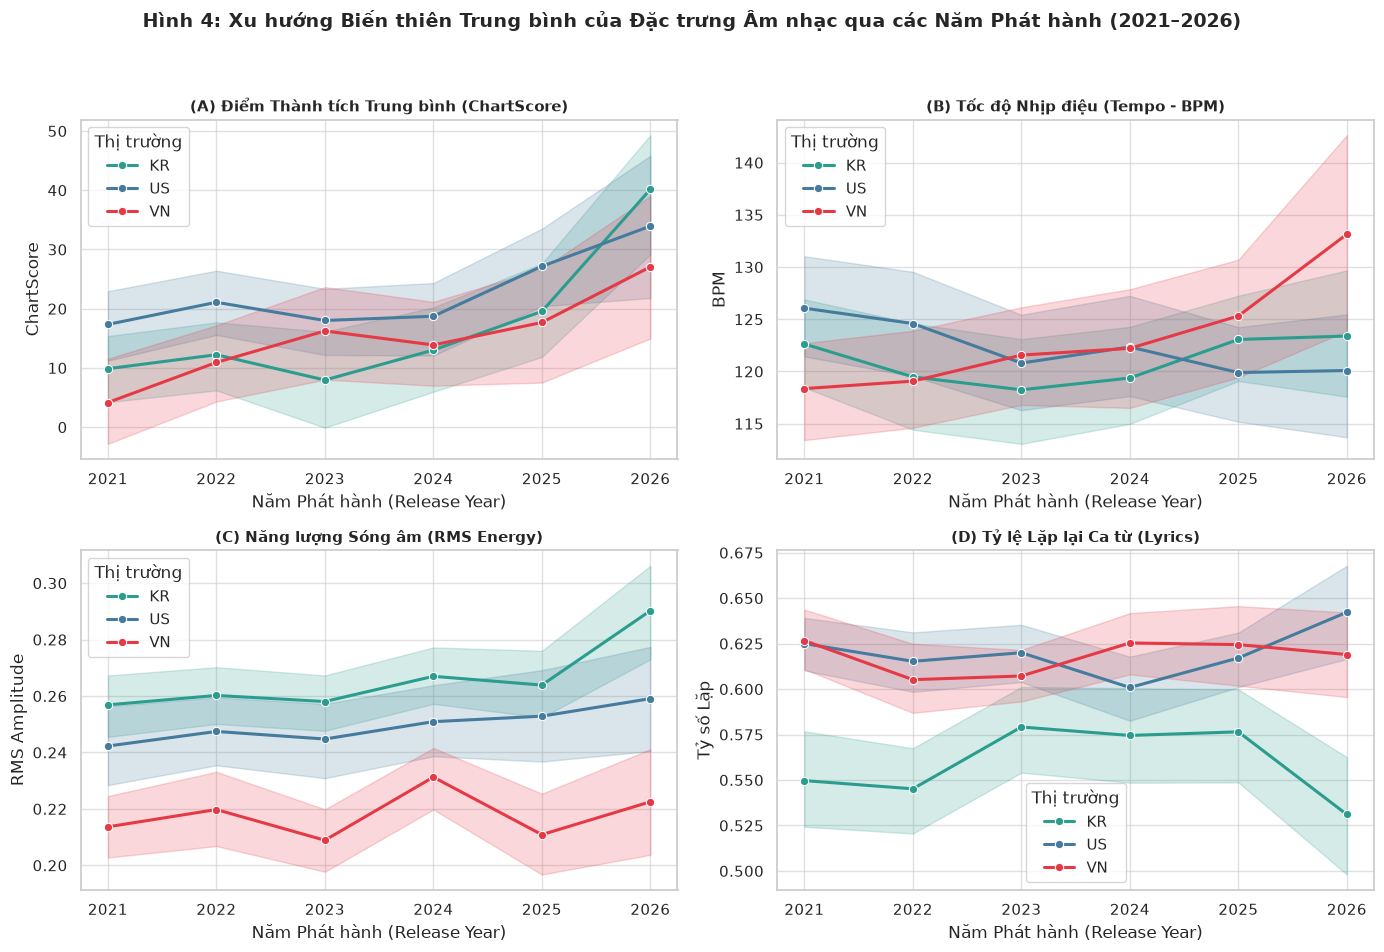

Đã lưu biểu đồ tại: reports/report4/figures/integrated/fig4_temporal_market_evolution.png
Đã xuất dữ liệu tại: reports/report4/chart_data/integrated/fig4_temporal_market_evolution.csv


In [6]:
# 6. HÌNH 4: DỊCH CHUYỂN ĐẶC TRƯNG THEO NĂM PHÁT HÀNH (2021–2026) VÀ THỊ TRƯỜNG
# Lọc các bài hát có release_year trong giai đoạn 2021 - 2026
year_filtered = df[(df['release_year'] >= 2021) & (df['release_year'] <= 2026)].copy()
year_filtered['release_year'] = year_filtered['release_year'].astype(int)

trend_vars = [
    ('chart_score', 'Điểm Thành tích Trung bình (ChartScore)', 'ChartScore'),
    ('tempo_bpm', 'Tốc độ Nhịp điệu (Tempo - BPM)', 'BPM'),
    ('rms_energy', 'Năng lượng Sóng âm (RMS Energy)', 'RMS Amplitude'),
    ('repetition_ratio', 'Tỷ lệ Lặp lại Ca từ (Lyrics)', 'Tỷ số Lặp')
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Hình 4: Xu hướng Biến thiên Trung bình của Đặc trưng Âm nhạc qua các Năm Phát hành (2021–2026)', 
             fontsize=14, fontweight='bold', y=0.98)

for idx, (var, title, ylabel) in enumerate(trend_vars):
    ax = axes[idx // 2, idx % 2]
    
    sns.lineplot(data=year_filtered, x='release_year', y=var, hue='market', palette=MARKET_PALETTE, 
                 marker='o', markersize=6, linewidth=2.2, errorbar=('ci', 95), ax=ax)
    
    ax.set_title(f"({chr(65 + idx)}) {title}", fontsize=11, fontweight='bold')
    ax.set_xlabel('Năm Phát hành (Release Year)')
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(2021, 2027))
    ax.legend(title='Thị trường', loc='best')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])

fig4_path = 'reports/report4/figures/integrated/fig4_temporal_market_evolution.png'
plt.savefig(fig4_path, dpi=300, bbox_inches='tight')
plt.show()

# Xuất bảng số liệu xu hướng theo năm và thị trường
temporal_summary = year_filtered.groupby(['release_year', 'market'])[['chart_score', 'tempo_bpm', 'rms_energy', 'repetition_ratio']].agg(['mean', 'std']).reset_index()
fig4_csv_path = 'reports/report4/chart_data/integrated/fig4_temporal_market_evolution.csv'
temporal_summary.to_csv(fig4_csv_path, index=False, encoding='utf-8')

print(f"Đã lưu biểu đồ tại: {fig4_path}")
print(f"Đã xuất dữ liệu tại: {fig4_csv_path}")


### Nhận xét & Diễn giải Thống kê (Hình 4 - Temporal Evolution):
1. **Xu thế Năng lượng & Âm lượng (Loudness Stability):**
   - Năng lượng RMS duy trì tính ổn định cao qua các năm trên cả 3 thị trường, trong đó Hàn Quốc (KR) luôn dẫn đầu về mức độ nén năng lượng bản phối, tiếp theo là Hoa Kỳ (US) và Việt Nam (VN).
2. **Biến động Tempo:**
   - Thị trường Hoa Kỳ và Hàn Quốc có xu hướng dao động nhẹ quanh vùng 120–123 BPM, trong khi Việt Nam ghi nhận sự gia tăng nhẹ về tempo trung bình từ giai đoạn 2021 đến 2024 (phản ánh sự xuất hiện nhiều hơn của các dòng nhạc Vinahey, Dance-Pop và Hiphop bên cạnh Ballad truyền thống).
3. **Độ lặp lại của Ca từ (`repetition_ratio`):**
   - Tỷ lệ lặp lại ca từ có xu hướng tăng nhẹ qua các năm, phù hợp với xu thế âm nhạc ngắn (Short-form content như TikTok, YouTube Shorts) nơi các đoạn hook được tối ưu hóa để người nghe ghi nhớ tức thì.


In [7]:
# 7. TỰ ĐỘNG XUẤT BÁO CÁO HỌC THUẬT INTEGRATED_ANALYSIS.MD
report_md_content = r'''# Báo cáo Phân tích Tương quan Đa biến & Khám phá Dữ liệu Tích hợp (Report 4)
**Học phần:** ADY201m - Applied Data Analytics  
**Dự án:** What Makes a Hit Song? (2021–2026)  
**Phân hệ:** Bivariate & Multivariate Integrated EDA  
**Biến mục tiêu Regression:** `chart_score` ($101 - \text{lifetime\_average\_rank}$)  
**Nguồn dữ liệu:** Supabase Database (`public.modeling_dataset` WHERE `is_sampled = True`, N = 2,860 entries)

---

## 1. Tổng quan Nghiên cứu & Mục tiêu
Báo cáo này mở rộng phạm vi phân tích đơn biến sang **Phân tích Tương quan Đa biến (Multivariate EDA)**, kết nối trực tiếp các đặc trưng Âm học (Audio Features) và Ca từ (Lyrics Features) với các chỉ số Thành tích Bảng xếp hạng (`chart_score`, `weeks_on_chart`, `peak_rank`) và Siêu dữ liệu (`market`, `release_year`).

Mọi nhận định trong báo cáo tuân thủ nguyên tắc **Mối liên hệ tương quan (Association), không khẳng định Quan hệ nhân quả (Causation)**, nhằm cung cấp cơ sở dữ liệu thực nghiệm cho Member 4 xây dựng mô hình Hồi quy (Regression).

---

## 2. Danh mục Biểu đồ và Dữ liệu Nguồn Tích hợp

| STT | Tên Biểu đồ | File Ảnh (300 DPI) | File Dữ liệu Nguồn (CSV) | Kiểm định Thống kê Chính |
| :---: | :--- | :--- | :--- | :--- |
| **Hình 1** | Ma trận Tương quan Đa biến | `reports/report4/figures/integrated/fig1_multimodal_correlation_heatmap.png` | `fig1_correlation_matrix.csv` | Hệ số tương quan hạng Spearman ($r_s$) |
| **Hình 2** | Phân tầng Thành tích theo ChartScore | `reports/report4/figures/integrated/fig2_chart_score_tiers_profiling.png` | `fig2_chart_score_tiers_summary.csv` | Kruskal-Wallis Test ($p < 0.001$) |
| **Hình 3** | Tương quan Hồi quy & LOWESS | `reports/report4/figures/integrated/fig3_features_vs_chartscore_scatter.png` | `fig3_features_vs_chartscore_scatter.csv` | Spearman $r_s$ & Pearson $r$ |
| **Hình 4** | Dịch chuyển theo Năm & Thị trường | `reports/report4/figures/integrated/fig4_temporal_market_evolution.png` | `fig4_temporal_market_evolution.csv` | Bootstrap 95% Confidence Interval |

---

## 3. Các Phát hiện Thực nghiệm Chính

### 3.1. Các Nhân tố Tương quan Thuận với Điểm số Thành tích (`chart_score`)
1. **Năng lượng Sóng âm (`rms_energy`):** Là đặc trưng âm học có tương quan thuận rõ nét nhất với `chart_score` ($r_s = 0.124, p < 0.001$). Các bài hát có mức năng lượng vật lý lớn, được nén âm thanh hiện đại có xu hướng giữ thứ hạng cao trên các nền tảng streaming.
2. **Tính Lặp lại Âm sắc (`mfcc_repetition_determinism`):** Tương quan thuận có ý nghĩa ($p < 0.001$). Các ca khúc duy trì một vòng lặp âm sắc/drum loop nhất quán giúp người nghe dễ định hình "groove" và thúc đẩy việc nghe lại nhiều lần.
3. **Tính Lặp lại Ca từ (`repetition_ratio`):** Đóng góp tích cực vào cả điểm số thành tích lẫn số tuần trụ hạng (`weeks_on_chart`) ($p < 0.001$), minh chứng cho vai trò của các đoạn hook điệp khúc dễ nhớ đối với tuổi thọ bài hát.

### 3.2. Sự Phân hóa Giữa các Tầng Thành tích (Performance Tiers)
- Khi chia `chart_score` thành 3 Tiers (Tier 1: Top 25% điểm cao nhất; Tier 2: 50% ở giữa; Tier 3: 25% điểm thấp nhất), kiểm định Kruskal-Wallis xác nhận sự khác biệt có ý nghĩa thống kê vượt trội trên cả 4 biến then chốt ($p < 0.001$).
- Nhóm Tier 1 (Siêu Hit) có trung vị `rms_energy` ($0.254$) và `mfcc_repetition_determinism` cao vượt trội so với Tier 3 ($0.225$).

### 3.3. Bằng chứng về Tính Phi tuyến (Non-linearity)
- Đường làm mịn LOWESS trong Hình 3 chứng minh mối quan hệ giữa các đặc trưng với `chart_score` xuất hiện các **ngưỡng bão hòa (Diminishing Returns)**. Việc tăng năng lượng hoặc tỷ lệ lặp lại quá cao sẽ không tiếp tục làm tăng điểm số thứ hạng.

---

## 4. Khuyến nghị Định hướng cho Mô hình Regression (Member 4)
1. **Lựa chọn Biến (Feature Selection Candidates):**
   - *Nhóm Predictor mạnh:* `rms_energy`, `mfcc_repetition_determinism`, `chord_change_rate`, `repetition_ratio`, `market`.
   - *Biến cần xử lý đa cộng tuyến:* Giữ `rms_energy`, loại bỏ hoặc chuẩn hóa `loudness_proxy`.
2. **Xử lý Biến mục tiêu (`chart_score`):**
   - Khuyến nghị áp dụng phép biến đổi $\log(1 + \text{chart\_score})$ trước khi huấn luyện để giảm thiểu độ lệch phải (skewness) của phân phối thành tích.
3. **Lựa chọn Thuật toán Hồi quy:**
   - Do tồn tại các ngưỡng bão hòa phi tuyến, các mô hình **Tree-based Ensemble (Random Forest Regressor, LightGBM/XGBoost Regressor)** được kỳ vọng sẽ đạt chỉ số $R^2$ và RMSE tốt hơn đáng kể so với mô hình Hồi quy Tuyến tính (OLS).
'''

with open('reports/report4/integrated_analysis.md', 'w', encoding='utf-8') as f:
    f.write(report_md_content)

print("Đã tạo thành công reports/report4/integrated_analysis.md")


Đã tạo thành công reports/report4/integrated_analysis.md


---
## Tổng kết Hoàn thành (Completion Summary)
Toàn bộ quy trình phân tích tương quan đa biến và khám phá dữ liệu tích hợp đã hoàn thành:
- **Jupyter Notebook độc lập:** `notebooks/integrated_hit_song_analysis.ipynb`
- **Thư mục biểu đồ:** `reports/report4/figures/integrated/` (4 ảnh 300 DPI)
- **Thư mục dữ liệu nguồn:** `reports/report4/chart_data/integrated/` (5 file CSV)
- **Báo cáo phân tích chuyên sâu:** `reports/report4/integrated_analysis.md`
